# YOLOv8 PPE Detection — Google Colab Training

**Before running:**
1. `Runtime → Change runtime type → T4 GPU`
2. Upload your dataset to Google Drive so the path is:
   `My Drive/ppe-dataset-yolov8/` (or change `DRIVE_DATASET_PATH` below)
3. Dataset must have `train/`, `valid/`, `test/` folders with `images/` + `labels/` inside, and a `.yaml` file.
4. Run all cells top to bottom (`Runtime → Run all`).

## Step 1 — Mount Google Drive + Config

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Getting Dataset here in Colab Disk

In [ ]:
!gdown --id 1hXL8W0fduVrUjiYCE2ZRFY2bPwJLlCrP

/usr/local/lib/python3.12/dist-packages/gdown/__main__.py:139: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From (original): https://drive.google.com/uc?id=1hXL8W0fduVrUjiYCE2ZRFY2bPwJLlCrP
From (redirected): https://drive.google.com/uc?id=1hXL8W0fduVrUjiYCE2ZRFY2bPwJLlCrP&confirm=t&uuid=1af8491f-d46f-4eed-acce-9fb94c8a6aaa
To: /content/PPE_Dataset.zip
100% 2.53G/2.53G [01:25<00:00, 29.4MB/s]
unzip:  cannot find or open your_dataset.zip, your_dataset.zip.zip or your_dataset.zip.ZIP.


In [ ]:


DRIVE_DATASET_PATH = "/content/PPE_Dataset.zip"


WORKING_DIR = "/content/working"

import os
os.makedirs(WORKING_DIR, exist_ok=True)

print(f"Drive dataset path : {DRIVE_DATASET_PATH}")
print(f"Working dir        : {WORKING_DIR}")
print(f"Drive dataset exists: {os.path.exists(DRIVE_DATASET_PATH)}")
if not os.path.exists(DRIVE_DATASET_PATH):
    print()
    print("❌ Dataset folder not found on Drive!")
    print("   Make sure you uploaded the dataset to Google Drive at:")
    print(f"   {DRIVE_DATASET_PATH}")
    print("   Then change DRIVE_DATASET_PATH above if your folder name differs.")
else:
    print("✅ Dataset folder found on Drive.")

Drive dataset path : /content/PPE_Dataset.zip
Working dir        : /content/working
Drive dataset exists: True
✅ Dataset folder found on Drive.


In [ ]:
import os

# 1. Identify ZIP path (check if DRIVE_DATASET_PATH is zip or folder)
ZIP_PATH = DRIVE_DATASET_PATH if DRIVE_DATASET_PATH.endswith('.zip') else DRIVE_DATASET_PATH + ".zip"
EXTRACT_DIR = os.path.join(WORKING_DIR, "ppe_data")

# 2. Run Unzip
if os.path.exists(ZIP_PATH):
    print(f"Unzipping {ZIP_PATH} to local disk...")
    !unzip -q "{ZIP_PATH}" -d "{EXTRACT_DIR}"
    print(f"✅ Extraction complete: {EXTRACT_DIR}")
else:
    print(f"❌ ZIP not found at {ZIP_PATH}")

# 3. List contents to verify
print("Extracted folders:", os.listdir(EXTRACT_DIR) if os.path.exists(EXTRACT_DIR) else "None")

Unzipping /content/PPE_Dataset.zip to local disk...
✅ Extraction complete: /content/working/ppe_data
Extracted folders: ['README.dataset.txt', 'data.yaml', 'README.roboflow.txt', 'train', 'valid', 'test']


## Step 2 — Install Dependencies

In [ ]:
# Colab already has PyTorch with CUDA — just install ultralytics
!pip install ultralytics -q
!pip install pyyaml -q
print("✅ Dependencies installed.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 57.0 MB/s eta 0:00:00
✅ Dependencies installed.


## Step 3 — GPU Check

In [ ]:
import torch
print("=" * 55)
print(f"  PyTorch   : {torch.__version__}")
print(f"  GPU ready : {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"  GPU name  : {torch.cuda.get_device_name(0)}")
    mem = torch.cuda.get_device_properties(0).total_memory / 1e9
    print(f"  GPU RAM   : {mem:.1f} GB")
else:
    print("  ⚠️  No GPU detected!")
    print("  Go to Runtime → Change runtime type → Hardware accelerator → T4 GPU")
    print("  Then re-run all cells.")
print("=" * 55)

  PyTorch   : 2.10.0+cu128
  GPU ready : True
  GPU name  : Tesla T4
  GPU RAM   : 15.6 GB


## Step 5 — Explore Dataset Structure

In [ ]:
import os

DATASET_ROOT = "/content/working/ppe_data"

print(f"Dataset at: {DATASET_ROOT}\n")
for root, dirs, files in os.walk(DATASET_ROOT):
    depth = root.replace(DATASET_ROOT, "").count(os.sep)
    if depth > 3:
        continue
    indent = "  " * depth
    print(f"{indent}📁 {os.path.basename(root)}/")
    if depth <= 2:
        sub = "  " * (depth + 1)
        imgs = [f for f in files if f.lower().endswith(('.jpg', '.png', '.jpeg'))]
        txts = [f for f in files if f.endswith('.txt')]
        ymls = [f for f in files if f.endswith(('.yaml', '.yml'))]
        if imgs: print(f"{sub}📸 {len(imgs)} images")
        if txts: print(f"{sub}🏷  {len(txts)} label .txt files")
        if ymls: print(f"{sub}📄 yaml: {ymls}")

print("\n✅ You should see train/, valid/, test/ folders")
print("   Each should have images/ and labels/ inside.")

Dataset at: /content/working/ppe_data

📁 ppe_data/
  🏷  2 label .txt files
  📄 yaml: ['data.yaml']
  📁 train/
    📁 images/
      📸 30765 images
    📁 labels/
      🏷  30765 label .txt files
  📁 valid/
    📁 images/
      📸 8814 images
    📁 labels/
      🏷  8814 label .txt files
  📁 test/
    📁 images/
      📸 4423 images
    📁 labels/
      🏷  4423 label .txt files

✅ You should see train/, valid/, test/ folders
   Each should have images/ and labels/ inside.


## Step 6 — Auto-detect Paths + Read Class Names

In [ ]:
import os, glob, yaml
from pathlib import Path

def find_folder(root, name):
    for dirpath, dirnames, _ in os.walk(root):
        if name in dirnames:
            return os.path.join(dirpath, name)
    return None

def find_images_dir(split_dir):
    if split_dir is None or not os.path.exists(split_dir):
        return None
    images_sub = os.path.join(split_dir, "images")
    if os.path.exists(images_sub):
        return images_sub
    return split_dir

def find_labels_dir(split_dir):
    if split_dir is None or not os.path.exists(split_dir):
        return None
    labels_sub = os.path.join(split_dir, "labels")
    if os.path.exists(labels_sub):
        return labels_sub
    return None

def count_images(folder):
    if folder is None or not os.path.exists(folder):
        return 0
    return len(
        glob.glob(os.path.join(folder, "*.jpg"))  +
        glob.glob(os.path.join(folder, "*.jpeg")) +
        glob.glob(os.path.join(folder, "*.png"))
    )

# Find split directories
train_split = find_folder(DATASET_ROOT, "train")
valid_split = find_folder(DATASET_ROOT, "valid") or find_folder(DATASET_ROOT, "val")
test_split  = find_folder(DATASET_ROOT, "test")

TRAIN_IMGS = find_images_dir(train_split)
VALID_IMGS = find_images_dir(valid_split)
TEST_IMGS  = find_images_dir(test_split)
TRAIN_LBLS = find_labels_dir(train_split)
VALID_LBLS = find_labels_dir(valid_split)

if TRAIN_IMGS is None:
    raise RuntimeError(
        "❌ Could not find train images folder!\n"
        "   Check Step 5 output to see actual dataset structure."
    )
if VALID_IMGS is None:
    raise RuntimeError(
        "❌ Could not find valid/val images folder!\n"
        "   Check Step 5 output to see actual dataset structure."
    )

print("Detected paths:")
print(f"  Train images : {TRAIN_IMGS}  ({count_images(TRAIN_IMGS)} images)")
print(f"  Valid images : {VALID_IMGS}  ({count_images(VALID_IMGS)} images)")
print(f"  Test  images : {TEST_IMGS}   ({count_images(TEST_IMGS)} images)")
print(f"  Train labels : {TRAIN_LBLS}")
print(f"  Valid labels : {VALID_LBLS}")

# Read class names from YAML
yaml_files = (
    glob.glob(os.path.join(DATASET_ROOT, "**", "*.yaml"), recursive=True) +
    glob.glob(os.path.join(DATASET_ROOT, "**", "*.yml"),  recursive=True)
)

if not yaml_files:
    raise FileNotFoundError(
        "❌ No .yaml file found in dataset!\n"
        "   Dataset must include a data.yaml with class names."
    )

with open(yaml_files[0], "r") as f:
    orig_cfg = yaml.safe_load(f)

CLASS_NAMES = orig_cfg.get("names", [])
NUM_CLASSES = orig_cfg.get("nc", len(CLASS_NAMES))

if not CLASS_NAMES:
    raise ValueError("❌ Class names list is empty in data.yaml!")

print(f"\n  Classes ({NUM_CLASSES}): {CLASS_NAMES}")
print("\n✅ All paths detected.")

Detected paths:
  Train images : /content/working/ppe_data/train/images  (30765 images)
  Valid images : /content/working/ppe_data/valid/images  (8814 images)
  Test  images : /content/working/ppe_data/test/images   (4423 images)
  Train labels : /content/working/ppe_data/train/labels
  Valid labels : /content/working/ppe_data/valid/labels

  Classes (14): ['Fall-Detected', 'Gloves', 'Goggles', 'Hardhat', 'Ladder', 'Mask', 'NO-Gloves', 'NO-Goggles', 'NO-Hardhat', 'NO-Mask', 'NO-Safety Vest', 'Person', 'Safety Cone', 'Safety Vest']

✅ All paths detected.


## Step 7 — Build Fixed YAML (correct absolute paths)

In [ ]:
import yaml, os
from pathlib import Path

def make_relative(full_path, root):
    if full_path is None:
        return None
    try:
        return str(Path(full_path).relative_to(root))
    except ValueError:
        return full_path

train_rel = make_relative(TRAIN_IMGS, DATASET_ROOT)
valid_rel  = make_relative(VALID_IMGS, DATASET_ROOT)
test_rel   = make_relative(TEST_IMGS,  DATASET_ROOT)

fixed_cfg = {
    "path"  : DATASET_ROOT,
    "train" : train_rel,
    "val"   : valid_rel,
    "nc"    : NUM_CLASSES,
    "names" : CLASS_NAMES,
}
if test_rel is not None:
    fixed_cfg["test"] = test_rel

FIXED_YAML = os.path.join(WORKING_DIR, "ppe_dataset.yaml")

with open(FIXED_YAML, "w") as f:
    yaml.dump(fixed_cfg, f, default_flow_style=False, sort_keys=False)

print(f"Fixed YAML saved to: {FIXED_YAML}")
print("\nContents:")
print("─" * 40)
with open(FIXED_YAML) as f:
    print(f.read())
print("─" * 40)
print("✅ YAML ready")

Fixed YAML saved to: /content/working/ppe_dataset.yaml

Contents:
────────────────────────────────────────
path: /content/working/ppe_data
train: train/images
val: valid/images
nc: 14
names:
- Fall-Detected
- Gloves
- Goggles
- Hardhat
- Ladder
- Mask
- NO-Gloves
- NO-Goggles
- NO-Hardhat
- NO-Mask
- NO-Safety Vest
- Person
- Safety Cone
- Safety Vest
test: test/images

────────────────────────────────────────
✅ YAML ready


## Step 8 — Preview Training Images with Ground-Truth Boxes

Training samples with ground-truth boxes:


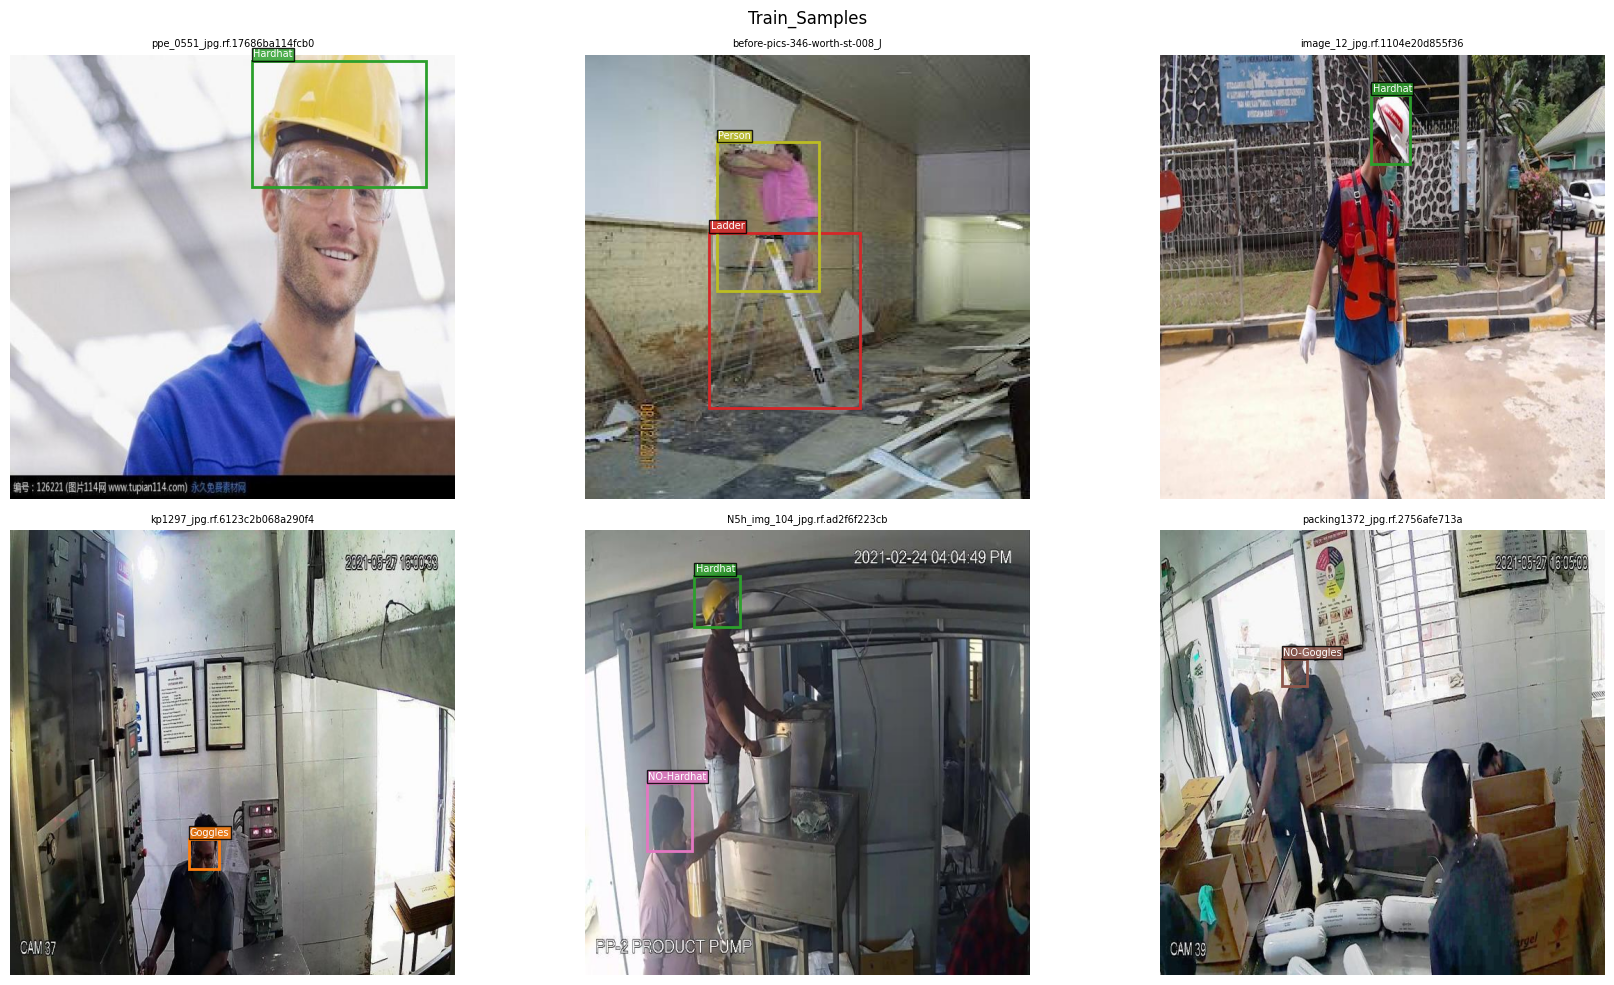

  Saved → /content/working/Train_Samples.png

Validation samples:


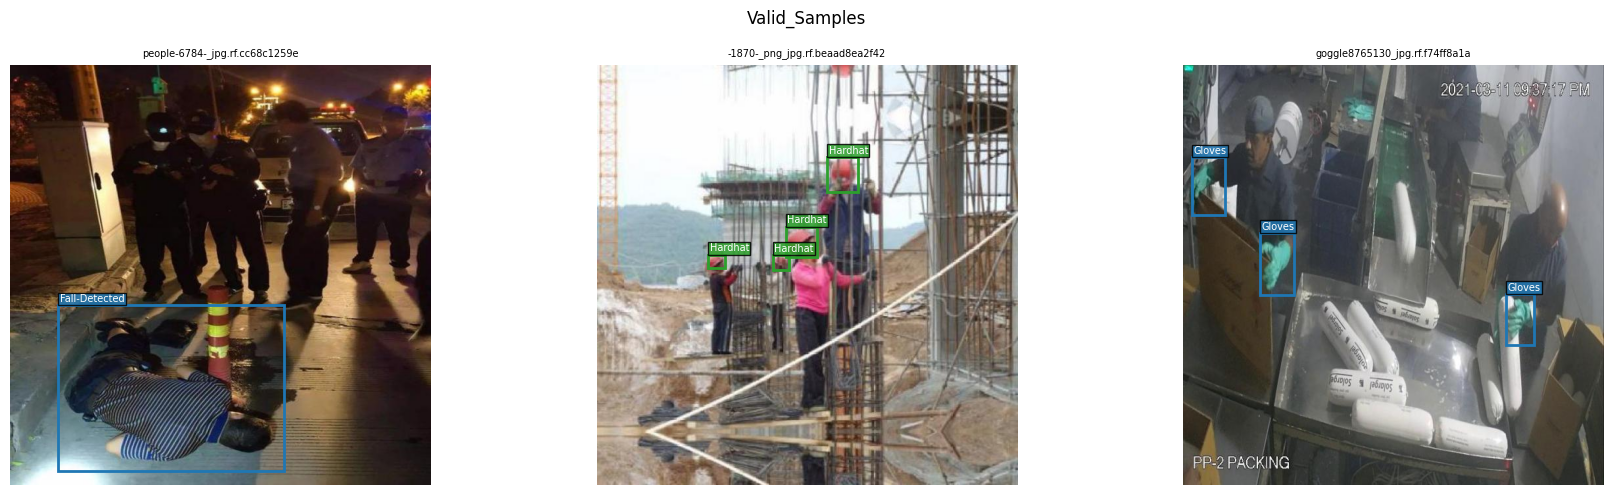

  Saved → /content/working/Valid_Samples.png


In [ ]:
import glob, random
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import matplotlib.patches as patches
from pathlib import Path

def show_images_with_labels(img_dir, label_dir, class_names, n=6, title="Samples"):
    img_paths = (
        glob.glob(os.path.join(img_dir, "*.jpg"))  +
        glob.glob(os.path.join(img_dir, "*.jpeg")) +
        glob.glob(os.path.join(img_dir, "*.png"))
    )
    if not img_paths:
        print(f"No images in {img_dir}")
        return

    samples = random.sample(img_paths, min(n, len(img_paths)))
    n_cols = min(3, len(samples))
    n_rows = (len(samples) + n_cols - 1) // n_cols
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(6 * n_cols, 5 * n_rows))
    axes = np.array(axes).flatten()
    palette = plt.cm.tab10(np.linspace(0, 1, max(len(class_names), 1)))

    for ax, img_path in zip(axes, samples):
        img = mpimg.imread(img_path)
        h, w = img.shape[:2]
        ax.imshow(img)
        if label_dir is not None:
            lbl_path = os.path.join(label_dir, Path(img_path).stem + ".txt")
            if os.path.exists(lbl_path):
                with open(lbl_path) as f:
                    for line in f:
                        parts = line.strip().split()
                        if len(parts) < 5:
                            continue
                        cid = int(parts[0])
                        cx, cy, bw, bh = (float(p) for p in parts[1:5])
                        x1 = (cx - bw / 2) * w
                        y1 = (cy - bh / 2) * h
                        color = palette[cid % len(palette)]
                        ax.add_patch(patches.Rectangle(
                            (x1, y1), bw * w, bh * h,
                            linewidth=2, edgecolor=color, facecolor="none"
                        ))
                        name = class_names[cid] if cid < len(class_names) else str(cid)
                        ax.text(x1 + 2, y1 - 5, name, color="white", fontsize=7,
                                bbox=dict(facecolor=color, alpha=0.85, pad=1))
        ax.set_title(Path(img_path).name[:30], fontsize=7)
        ax.axis("off")

    for ax in axes[len(samples):]:
        ax.axis("off")

    plt.suptitle(title, fontsize=12)
    plt.tight_layout()
    save_path = os.path.join(WORKING_DIR, title.replace(" ", "_") + ".png")
    plt.savefig(save_path, dpi=100, bbox_inches="tight")
    plt.show()
    print(f"  Saved → {save_path}")

print("Training samples with ground-truth boxes:")
show_images_with_labels(TRAIN_IMGS, TRAIN_LBLS, CLASS_NAMES, n=6, title="Train_Samples")

print("\nValidation samples:")
show_images_with_labels(VALID_IMGS, VALID_LBLS, CLASS_NAMES, n=3, title="Valid_Samples")

## Step 9 — Class Distribution (Check for Imbalance)

In [ ]:
from collections import Counter
import glob, os

def count_class_labels(label_dir, num_classes):
    counter = Counter()
    if label_dir is None or not os.path.exists(label_dir):
        return counter
    for lf in glob.glob(os.path.join(label_dir, "*.txt")):
        with open(lf) as f:
            for line in f:
                parts = line.strip().split()
                if parts:
                    try:
                        counter[int(parts[0])] += 1
                    except ValueError:
                        pass
    return counter

train_counts = count_class_labels(TRAIN_LBLS, NUM_CLASSES)
total = sum(train_counts.values())

print(f"Training label distribution (total: {total})")
print("─" * 55)
VIOLATION_CLASSES = [c for c in CLASS_NAMES if c.upper().startswith("NO-")]

for i, name in enumerate(CLASS_NAMES):
    n = train_counts.get(i, 0)
    pct = (n / total * 100) if total > 0 else 0
    bar = "█" * int(pct / 2)
    flag = "🚨" if name in VIOLATION_CLASSES else "  "
    print(f"  {flag} {name:<24} {n:>6}  ({pct:4.1f}%)  {bar}")

print("─" * 55)
print("  🚨 = PPE violation classes")
print()
for vc in VIOLATION_CLASSES:
    idx = CLASS_NAMES.index(vc) if vc in CLASS_NAMES else -1
    if idx >= 0:
        n = train_counts.get(idx, 0)
        if n < 200:
            print(f"  ⚠️  '{vc}' only has {n} labels — model may miss violations")
        else:
            print(f"  ✅ '{vc}' has {n} labels — sufficient")

Training label distribution (total: 76398)
───────────────────────────────────────────────────────
     Fall-Detected              3149  ( 4.1%)  ██
     Gloves                     3381  ( 4.4%)  ██
     Goggles                    2959  ( 3.9%)  █
     Hardhat                   28996  (38.0%)  ██████████████████
     Ladder                      734  ( 1.0%)  
     Mask                       1989  ( 2.6%)  █
  🚨 NO-Gloves                  4280  ( 5.6%)  ██
  🚨 NO-Goggles                 2817  ( 3.7%)  █
  🚨 NO-Hardhat                 9705  (12.7%)  ██████
  🚨 NO-Mask                    1577  ( 2.1%)  █
  🚨 NO-Safety Vest             1435  ( 1.9%)  
     Person                     1034  ( 1.4%)  
     Safety Cone                9843  (12.9%)  ██████
     Safety Vest                4499  ( 5.9%)  ██
───────────────────────────────────────────────────────
  🚨 = PPE violation classes

  ✅ 'NO-Gloves' has 4280 labels — sufficient
  ✅ 'NO-Goggles' has 2817 labels — sufficient
  ✅ 'NO-Hardhat'

## Step 10 — TRAIN THE MODEL (First time)


In [ ]:
# import os
# from tqdm import tqdm
# from ultralytics import YOLO

# # Disable W&B logging
# try:
#     import wandb
#     wandb.init(mode="disabled")
# except ImportError:
#     pass
# os.environ["WANDB_DISABLED"] = "true"

# os.chdir(WORKING_DIR)

# print("Loading YOLOv8m pretrained weights...")
# model = YOLO("yolov8m.pt")
# print("\nStarting training — ~30-60 min. Do not close tab.\n")

# TOTAL_EPOCHS = 100
# pbar = tqdm(
#     total=TOTAL_EPOCHS, desc="Training", unit="epoch",
#     bar_format="{l_bar}{bar}| {n_fmt}/{total_fmt} epochs [{elapsed}<{remaining}, {rate_fmt}]",
#     dynamic_ncols=True,
# )

# def _on_epoch_end(trainer):
#     metrics = trainer.metrics or {}
#     mAP  = metrics.get("metrics/mAP50(B)", 0)
#     loss = metrics.get("train/box_loss",   0)
#     pbar.set_postfix({"mAP50": f"{mAP:.3f}", "box_loss": f"{loss:.4f}"}, refresh=False)
#     pbar.update(1)

# model.add_callback("on_train_epoch_end", _on_epoch_end)

# try:
#     train_results = model.train(
#         data            = FIXED_YAML,
#         imgsz           = 640,
#         batch           = 16,       # 16 for Colab T4 (15GB VRAM); bump to 32 if using A100
#         cache           = True,     # cache images in RAM for speed on Colab
#         workers         = 2,
#         epochs          = 100,
#         patience        = 20,
#         device          = 0,
#         optimizer       = "AdamW",
#         lr0             = 0.001,
#         lrf             = 0.1,
#         momentum        = 0.937,
#         weight_decay    = 0.0005,
#         warmup_epochs   = 3,
#         warmup_momentum = 0.8,
#         hsv_h           = 0.015,
#         hsv_s           = 0.7,
#         hsv_v           = 0.4,
#         degrees         = 5.0,
#         translate       = 0.1,
#         scale           = 0.5,
#         fliplr          = 0.5,
#         flipud          = 0.0,
#         mosaic          = 1.0,
#         mixup           = 0.1,
#         copy_paste      = 0.0,
#         project         = "ppe_runs",
#         name            = "ppe_model_v1",
#         save            = True,
#         save_period     = 20,
#         plots           = True,
#         verbose         = True,
#     )
# finally:
#     pbar.close()

# RESULTS_DIR = os.path.join(WORKING_DIR, "ppe_runs", "ppe_model_v1")
# BEST_PT     = os.path.join(RESULTS_DIR, "weights", "best.pt")

# if not os.path.exists(BEST_PT):
#     raise FileNotFoundError(f"❌ best.pt not found at {BEST_PT}")

# print(f"\n✅ TRAINING DONE — {os.path.getsize(BEST_PT)/1024/1024:.1f} MB → {BEST_PT}")

In [ ]:
!pip install --upgrade gdown

# 2. Define the Folder ID from Account A
folder_id = '17KzXT3QJiFRsIZ5y2PDAWyfyj5-4Firc'

# 3. Download the entire folder
# Use the --folder flag to indicate you are downloading a directory
!gdown --folder {folder_id}

  Attempting uninstall: gdown
    Found existing installation: gdown 5.2.1
    Uninstalling gdown-5.2.1:
      Successfully uninstalled gdown-5.2.1
Retrieving folder contents
Retrieving folder 1jRmc_g2BJEe8pYUVBeRNJ4KmUZGbq1e1 detect
Retrieving folder 1CXd-PxvAxSJTNQbxMpfUQmqxJOkqCFT6 ppe_runs
Retrieving folder 1lUNotQ88y4Pfj9jRTZ8l9wYWywKdUVif ppe_model_v1
Retrieving folder 15vJZJ5M-1bktzRI5Hd9DLEjvA43uGLmY weights
Processing file 1MQjsRNo8leakNihZyiArrLMe74byf99w best.pt
Processing file 1ybIkceTr3EXCsC827679Enh17VvVYglh last.pt
Processing file 1tELAe8WK79JFQBbE9rqZdEuDLL09F1P1 args.yaml
Processing file 1tuCAwIaOFUoxi17WQvKHzr-161WdSsi4 labels.jpg
Processing file 1dd0YvlF69IiG5iVNCHiT4kchdf3xC4Bg results.csv
Retrieving folder contents completed
Building directory structure
Building directory structure completed
Downloading...
From (original): https://drive.google.com/uc?id=1MQjsRNo8leakNihZyiArrLMe74byf99w
From (redirected): https://drive.google.com/uc?id=1MQjsRNo8leakNihZyiArrLMe74by

## Resuming From last Epoch

In [ ]:
import os
from tqdm import tqdm
from ultralytics import YOLO


os.environ["WANDB_DISABLED"] = "true"
os.chdir(WORKING_DIR)


# Load last.pt from Drive
model = YOLO('/content/working/Weights_1/detect/ppe_runs/ppe_model_v1/weights/last.pt')

TOTAL_EPOCHS = 40
pbar = tqdm(
    total=TOTAL_EPOCHS, desc="Training", unit="epoch",
    bar_format="{l_bar}{bar}| {n_fmt}/{total_fmt} epochs [{elapsed}<{remaining}, {rate_fmt}]",
    dynamic_ncols=True,
)

def _on_epoch_end(trainer):
    metrics = trainer.metrics or {}
    mAP  = metrics.get("metrics/mAP50(B)", 0)
    loss = metrics.get("train/box_loss",   0)
    pbar.set_postfix({"mAP50": f"{mAP:.3f}", "box_loss": f"{loss:.4f}"}, refresh=False)
    pbar.update(1)

model.add_callback("on_train_epoch_end", _on_epoch_end)

try:
    train_results = model.train(
        resume = True,   # ← reads epoch/optimizer state from last.pt
        data   = FIXED_YAML,
        patience=20,
        epochs=TOTAL_EPOCHS
    )
finally:
    pbar.close()

Training:   0%|          | 0/40 epochs [00:00<?, ?epoch/s]

Ultralytics 8.4.39 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=True, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/working/ppe_dataset.yaml, degrees=5.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.001, lrf=0.1, mask_ratio=4, max_det=300, mixup=0.1, mode=train, model=/content/working/Weights_1/detect/ppe_runs/ppe_model_v1/weights/last.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=ppe_model_v1, nbs=64, nms=False, opset=N

Training:   2%|▎         | 1/40 epochs [18:51<12:15:44, 1131.91s/epoch]

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 276/276 2.0it/s 2:18
                   all       8814      22077      0.736      0.742      0.733      0.434

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
     13/100      6.71G      1.376      1.119        1.4         53        640: 100% ━━━━━━━━━━━━ 1923/1923 1.8it/s 18:16


Training:   5%|▌         | 2/40 epochs [39:30<12:36:31, 1194.50s/epoch]

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 276/276 2.1it/s 2:12
                   all       8814      22077       0.68      0.753      0.734      0.431

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
     14/100      6.71G      1.367      1.112      1.403         55        640: 11% ━─────────── 211/1923 2.0it/s 1:59<14:19


Training:   5%|▌         | 2/40 epochs [43:44<13:51:03, 1312.20s/epoch]


KeyboardInterrupt: 

## Training with Augmentation

In [ ]:
import os
from tqdm import tqdm
from ultralytics import YOLO

os.environ["WANDB_DISABLED"] = "true"
os.chdir(WORKING_DIR)

model = YOLO('/content/drive/MyDrive/Weights_Epoch_/detect/ppe_runs/ppe_model_v1/weights/last.pt')

TOTAL_EPOCHS = 35
pbar = tqdm(
    total=TOTAL_EPOCHS, desc="Training", unit="epoch",
    bar_format="{l_bar}{bar}| {n_fmt}/{total_fmt} epochs [{elapsed}<{remaining}, {rate_fmt}]",
    dynamic_ncols=True,
)

def _on_epoch_end(trainer):
    metrics = trainer.metrics or {}
    mAP  = metrics.get("metrics/mAP50(B)", 0)
    loss = metrics.get("train/box_loss",   0)
    pbar.set_postfix({"mAP50": f"{mAP:.3f}", "box_loss": f"{loss:.4f}"}, refresh=False)
    pbar.update(1)

model.add_callback("on_train_epoch_end", _on_epoch_end)

try:
    train_results = model.train(
        data          = FIXED_YAML,
        epochs        = TOTAL_EPOCHS,
        patience      = 30,
        imgsz         = 640,
        batch         = -1,
        optimizer     = 'AdamW',
        lr0           = 0.001,
        cos_lr        = True,
        warmup_epochs = 2,
        hsv_s         = 0.7,
        hsv_v         = 0.4,
        fliplr        = 0.5,
        mosaic        = 1.0,
        copy_paste    = 0.4,
        mixup         = 0.15,
        degrees       = 10.0,
        cls           = 2.5,
        val           = True,
        project       = 'ppe_runs',
        name          = 'ppe_model_v2',   # v2 = new run, won't overwrite v1
    )
finally:
    pbar.close()

Training:   0%|          | 0/35 epochs [00:00<?, ?epoch/s]

Ultralytics 8.4.39 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=-1, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=2.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.4, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/working/ppe_dataset.yaml, degrees=10.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=35, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.15, mode=train, model=/content/drive/MyDrive/Weights_Epoch_/detect/ppe_runs/ppe_model_v1/weights/last.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=ppe_model_v2, nbs=64, nms=F

Training:   0%|          | 0/35 epochs [00:44<?, ?epoch/s]


KeyboardInterrupt: 

## Saving Colab Disk Files

In [ ]:
import shutil

shutil.copytree(
    '/content/working/runs',
    '/content/drive/MyDrive/Weights_Epoch_13'
)
print("Done ✅")

Done ✅


## Step 11 — Show Training Plots

In [ ]:
from IPython.display import Image, display
import os

RESULTS_DIR = os.path.join(WORKING_DIR, "ppe_runs", "ppe_model_v1")

plots = [
    ("results.png",           "Training curves — mAP50 should rise, losses fall"),
    ("confusion_matrix.png",  "Confusion matrix — diagonal = correct detections"),
    ("PR_curve.png",          "Precision-Recall curve — hug top-right = great"),
    ("F1_curve.png",          "F1 score curve — peak should be above 0.65"),
]

print("Training result plots:\n")
for fname, desc in plots:
    fpath = os.path.join(RESULTS_DIR, fname)
    if os.path.exists(fpath):
        print(f"📊 {desc}")
        display(Image(fpath, width=820))
        print()
    else:
        print(f"  (not yet generated: {fname})\n")

print("Reading guide:")
print("  results.png      → mAP50 end value > 0.70 is good")
print("  confusion_matrix → strong diagonal = model classifies correctly")
print("  PR curve         → curve towards top-right = high accuracy")

Training result plots:

  (not yet generated: results.png)

  (not yet generated: confusion_matrix.png)

  (not yet generated: PR_curve.png)

  (not yet generated: F1_curve.png)

Reading guide:
  results.png      → mAP50 end value > 0.70 is good
  confusion_matrix → strong diagonal = model classifies correctly
  PR curve         → curve towards top-right = high accuracy


## Step 12 — Validation Metrics

In [ ]:
from ultralytics import YOLO
import os

BEST_PT = os.path.join(WORKING_DIR, "ppe_runs", "ppe_model_v1", "weights", "best.pt")
# trained_model = YOLO(BEST_PT)
trained_model = YOLO('/content/working/Weights_1/detect/ppe_runs/ppe_model_v1/weights/best.pt')
print("Running validation on held-out validation set...")
val_results = trained_model.val(
    data    = FIXED_YAML,
    imgsz   = 640,
    conf    = 0.001,
    iou     = 0.6,
    device  = 0,
    verbose = False,
)

MAP50   = val_results.box.map50
MAP5095 = val_results.box.map
PREC    = val_results.box.mp
RECALL  = val_results.box.mr

print("\n" + "=" * 55)
print("  VALIDATION METRICS")
print("=" * 55)
print(f"  mAP50      : {MAP50:.4f}   ← main score (aim >0.70)")
print(f"  mAP50-95   : {MAP5095:.4f}   ← stricter score")
print(f"  Precision  : {PREC:.4f}   ← % of alerts that are real")
print(f"  Recall     : {RECALL:.4f}   ← % of real violations caught")
print("=" * 55)

if   MAP50 >= 0.80: grade = "🟢 EXCELLENT — strong model"
elif MAP50 >= 0.70: grade = "🟡 GOOD — solid project"
elif MAP50 >= 0.55: grade = "🟠 DECENT — works in good conditions"
else:               grade = "🔴 WEAK — needs more data or epochs"

print(f"\n  Result: {grade}")
print(f"  Recall = {RECALL:.2f} → model catches {RECALL*100:.0f}% of real violations")
print(f"  For safety systems, Recall matters more than Precision.")

Running validation on held-out validation set...
Ultralytics 8.4.39 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 93 layers, 25,847,866 parameters, 0 gradients, 78.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1310.8±444.2 MB/s, size: 57.9 KB)
val: Scanning /content/working/ppe_data/valid/labels.cache... 8814 images, 210 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 8814/8814 2.6Git/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 551/551 2.1it/s 4:19
                   all       8814      22077      0.678      0.733      0.733      0.425
Speed: 1.1ms preprocess, 24.1ms inference, 0.0ms loss, 1.0ms postprocess per image
Results saved to /content/working/runs/detect/val

  VALIDATION METRICS
  mAP50      : 0.7329   ← main score (aim >0.70)
  mAP50-95   : 0.4247   ← stricter score
  Precision  : 0.6781   ← % of alerts that are real
  Recall     : 0.7326   ← % of real violat

## Step 13 — Per-Class AP Breakdown

In [ ]:
print("=" * 55)
print("  PER-CLASS PERFORMANCE")
print("=" * 55)

try:
    ap50_per_class = val_results.box.ap50
    violation_summary = []

    for cls_name, ap in zip(CLASS_NAMES, ap50_per_class):
        bar    = "█" * int(ap * 30)
        status = "✅" if ap >= 0.65 else ("⚠️ " if ap >= 0.40 else "❌")
        is_viol = cls_name in VIOLATION_CLASSES
        tag = "🚨" if is_viol else "  "
        print(f"  {tag} {status} {cls_name:<22}  AP50: {ap:.3f}  {bar}")
        if is_viol:
            violation_summary.append((cls_name, ap))

    print("\n  Violation class summary:")
    for name, ap in violation_summary:
        if   ap >= 0.65: note = "✅ good — will reliably catch violations"
        elif ap >= 0.40: note = "⚠️  moderate — some violations may be missed"
        else:            note = "❌ weak — will miss many violations"
        print(f"    {name}: {ap:.3f} → {note}")

except Exception as e:
    print(f"  Per-class AP not available: {e}")
    print("  Look at confusion_matrix.png instead.")

  PER-CLASS PERFORMANCE
  Per-class AP not available: name 'VIOLATION_CLASSES' is not defined
  Look at confusion_matrix.png instead.


## Step 14 — Visual Predictions on Test Images

In [ ]:
import glob, random, os
import numpy as np
import matplotlib.pyplot as plt

def count_images(folder):
    if folder is None or not os.path.exists(folder):
        return 0
    return len(
        glob.glob(os.path.join(folder, "*.jpg"))  +
        glob.glob(os.path.join(folder, "*.jpeg")) +
        glob.glob(os.path.join(folder, "*.png"))
    )

def visualise_predictions(model, img_dir, class_names, violation_classes,
                           n=8, conf=0.35, title="Predictions"):
    img_paths = (
        glob.glob(os.path.join(img_dir, "*.jpg"))  +
        glob.glob(os.path.join(img_dir, "*.jpeg")) +
        glob.glob(os.path.join(img_dir, "*.png"))
    )
    if not img_paths:
        print(f"No images found in {img_dir}")
        return 0, 0

    samples = random.sample(img_paths, min(n, len(img_paths)))
    n_cols = 4
    n_rows = (len(samples) + n_cols - 1) // n_cols
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(22, n_rows * 5))
    axes = np.array(axes).flatten()

    total_violations = 0
    images_with_violation = 0

    for ax, img_path in zip(axes, samples):
        preds = model.predict(source=img_path, conf=conf, iou=0.5, verbose=False)
        annotated = preds[0].plot(labels=True, conf=True, line_width=2)
        ax.imshow(annotated[:, :, ::-1])

        n_viol = 0
        if preds[0].boxes is not None and len(preds[0].boxes):
            for box in preds[0].boxes:
                cls_name = class_names[int(box.cls)]
                if cls_name in violation_classes:
                    n_viol += 1
                    total_violations += 1

        if n_viol > 0:
            images_with_violation += 1
            ax.set_title(f"🚨 {n_viol} VIOLATION(S)", color="red",
                         fontsize=10, fontweight="bold")
        else:
            ax.set_title("✅ PPE OK", color="green", fontsize=10, fontweight="bold")
        ax.axis("off")

    for ax in axes[len(samples):]:
        ax.axis("off")

    plt.suptitle(
        f"{title}  |  conf≥{conf}  |  "
        f"{images_with_violation}/{len(samples)} images had violations",
        fontsize=12
    )
    plt.tight_layout()
    save_path = os.path.join(WORKING_DIR, f"{title.replace(' ', '_')}.png")
    plt.savefig(save_path, dpi=100, bbox_inches="tight")
    plt.show()
    print(f"  Saved → {save_path}")
    return total_violations, len(samples)

img_source = TEST_IMGS if count_images(TEST_IMGS) > 0 else VALID_IMGS
src_label  = "test" if count_images(TEST_IMGS) > 0 else "valid"

print(f"Running visual predictions on {src_label} set ({count_images(img_source)} images)\n")
viols, tested = visualise_predictions(
    trained_model, img_source, CLASS_NAMES, VIOLATION_CLASSES,
    n=8, conf=0.35, title="Test_Predictions"
)
print(f"\n  Tested     : {tested} images")
print(f"  Violations : {viols} bounding boxes flagged")

Running visual predictions on test set (4423 images)



NameError: name 'VIOLATION_CLASSES' is not defined

## Step 15 — Speed Test

In [ ]:
import time, glob, os

print("=" * 55)
print("  INFERENCE SPEED TEST")
print("=" * 55)

speed_imgs = (
    glob.glob(os.path.join(img_source, "*.jpg")) +
    glob.glob(os.path.join(img_source, "*.png"))
)[:25]

if len(speed_imgs) == 0:
    print("  No images available for speed test.")
else:
    trained_model.predict(speed_imgs[0], conf=0.35, verbose=False)  # warmup

    start = time.time()
    for p in speed_imgs:
        trained_model.predict(p, conf=0.35, verbose=False)
    elapsed = time.time() - start

    ms_each = elapsed / len(speed_imgs) * 1000
    fps     = 1000 / ms_each

    print(f"  Images tested    : {len(speed_imgs)}")
    print(f"  Total time       : {elapsed:.2f}s")
    print(f"  Per image        : {ms_each:.1f}ms")
    print(f"  FPS equivalent   : {fps:.1f} FPS")

    if fps >= 20:
        speed_note = "✅ Very fast — handles live camera easily"
    elif fps >= 10:
        speed_note = "✅ Fast enough — use process_every_n_frames=2 in live system"
    elif fps >= 5:
        speed_note = "🟡 Moderate — use process_every_n_frames=3 in live system"
    else:
        speed_note = "🔴 Slow on Colab T4 — your local GPU may differ"

    print(f"  Status           : {speed_note}")

  INFERENCE SPEED TEST
  Images tested    : 25
  Total time       : 0.79s
  Per image        : 31.6ms
  FPS equivalent   : 31.7 FPS
  Status           : ✅ Very fast — handles live camera easily


## Step 16 — Save best.pt back to Google Drive + Final Summary

In [ ]:
import shutil, os, glob

# ── Save best.pt to Drive so it survives Colab session end ──
DRIVE_SAVE_DIR = "/content/drive/MyDrive/ppe_model_output"
os.makedirs(DRIVE_SAVE_DIR, exist_ok=True)

BEST_PT_SRC = os.path.join(WORKING_DIR, "ppe_runs", "ppe_model_v1", "weights", "best.pt")
BEST_PT_DST = os.path.join(DRIVE_SAVE_DIR, "best.pt")
YAML_DST    = os.path.join(DRIVE_SAVE_DIR, "ppe_dataset.yaml")

if os.path.exists(BEST_PT_SRC):
    shutil.copy2(BEST_PT_SRC, BEST_PT_DST)
    shutil.copy2(FIXED_YAML,  YAML_DST)
    size_mb = os.path.getsize(BEST_PT_DST) / 1024 / 1024
    print(f"✅ best.pt saved to Drive → {BEST_PT_DST}  ({size_mb:.1f} MB)")
    print(f"✅ YAML  saved to Drive → {YAML_DST}")
else:
    print("⚠️  best.pt not found — training may not have completed")

# Also copy training plots to Drive
RESULTS_DIR = os.path.join(WORKING_DIR, "ppe_runs", "ppe_model_v1")
for plot_name in ["results.png", "confusion_matrix.png", "PR_curve.png", "F1_curve.png"]:
    src = os.path.join(RESULTS_DIR, plot_name)
    if os.path.exists(src):
        shutil.copy2(src, os.path.join(DRIVE_SAVE_DIR, plot_name))

print()
print("=" * 55)
print("  FINAL TRAINING SUMMARY")
print("=" * 55)
print(f"  Model    : YOLOv8m fine-tuned on PPE dataset")
print(f"  Classes  : {NUM_CLASSES}  → {CLASS_NAMES}")
print(f"  mAP50    : {MAP50:.4f}")
print(f"  Precision: {PREC:.4f}")
print(f"  Recall   : {RECALL:.4f}")
print()
print(f"  Files saved to Drive: {DRIVE_SAVE_DIR}")
print(f"  → best.pt  (use this in your live inference system)")
print(f"  → ppe_dataset.yaml")
print(f"  → training plots")
print()
print("  To download best.pt:")
print("  Open Google Drive → ppe_model_output → right-click best.pt → Download")
print()
print("=" * 55)
print("  ✅ ALL DONE")
print("=" * 55)